In [3]:
import pandas as pd
import numpy as np
df = pd.read_csv('data.fix.csv')
print(df)

      brand                                               name  price  \
0        HP                   Victus 15-fb0157AX Gaming Laptop  17465   
1        HP                                15s-fq5007TU Laptop  13965   
2      Acer                               One 14 Z8-415 Laptop   9447   
3    Lenovo               Yoga Slim 6 14IAP8 82WU0095IN Laptop  20905   
4     Apple                    MacBook Air 2020 MGND3HN Laptop  24497   
..      ...                                                ...    ...   
888    Asus          Vivobook 15X 2023 K3504VAB-NJ321WS Laptop  15746   
889    Asus                     TUF A15 FA577RM-HQ032WS Laptop  38500   
890    Asus  ROG Zephyrus G14 2023 GA402XV-N2034WS Gaming L...  66497   
891    Asus  TUF Gaming F15 2023 FX507VU-LP083WS Gaming Laptop  45497   
892    Asus  TUF Gaming A15 2023 FA577XU-LP041WS Gaming Laptop  46197   

     spec_rating                      processor  \
0      73.000000      5th Gen AMD Ryzen 5 5600H   
1      60.000000   12

# Cleaning & Preprocessing

In [3]:
#RAM
df['ram_gb'] = df['Ram'].str.extract(r'(\d+)', expand=False).astype(int)

#threads
t = df['CPU'].str.extract(r'(\d+)\s*Threads', expand=False).astype(float)
c = df['CPU'].str.extract(r'(\d+)\s*Cores?', expand=False).astype(float)
df['threads'] = t.fillna(c)
df = df.dropna(subset=['threads']).reset_index(drop=True)
df['threads'] = df['threads'].astype(int)
#การ์ดจอแยก
df['gpu_dedicated'] = df['GPU'].str.contains(
    'NVIDIA|GeForce|RTX|GTX|Radeon RX|Radeon Pro|Arc', case=False).astype(int)
df

,brand,name,price,spec_rating,processor,CPU,Ram,Ram_type,ROM,ROM_type,GPU,display_size,resolution_width,resolution_height,OS,warranty,ram_gb,threads,gpu_dedicated
0,HP,Victus 15-fb0157AX Gaming Laptop,17465,73.000000,5th Gen AMD Ryzen 5 5600H,"Hexa Core, 12 Threads",8GB,DDR4,512GB,SSD,4GB AMD Radeon RX 6500M,15.6,1920.0,1080.0,Windows 11 OS,1,8,12,1
1,HP,15s-fq5007TU Laptop,13965,60.000000,12th Gen Intel Core i3 1215U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1,8,8,0
2,Acer,One 14 Z8-415 Laptop,9447,69.323529,11th Gen Intel Core i3 1115G4,"Dual Core, 4 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1,8,4,0
3,Lenovo,Yoga Slim 6 14IAP8 82WU0095IN Laptop,20905,66.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",16GB,LPDDR5,512GB,SSD,Intel Integrated Iris Xe,14.0,2240.0,1400.0,Windows 11 OS,1,16,16,0
4,Acer,Extensa EX214-53 Laptop,13997,62.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1,8,16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
878,Asus,Vivobook 15X 2023 K3504VAB-NJ321WS Laptop,15746,69.323529,13th Gen ‎Intel Core i3 1315U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Integrated Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1,8,8,0
879,Asus,TUF A15 FA577RM-HQ032WS Laptop,38500,71.000000,6th Gen AMD Ryzen 7 6800H,"Octa Core, 16 Threads",16GB,DDR,1TB,SSD,6GB NVIDIA GeForce RTX 3060,15.6,2560.0,1440.0,Windows 11 OS,1,16,16,1
880,Asus,ROG Zephyrus G14 2023 GA402XV-N2034WS Gaming L...,66497,89.000000,7th Gen AMD Ryzen 9 7940HS,"Octa Core, 16 Threads",32GB,DDR5,1TB,SSD,8GB NVIDIA GeForce RTX 4060,14.0,2560.0,1600.0,Windows 11 OS,1,32,16,1
881,Asus,TUF Gaming F15 2023 FX507VU-LP083WS Gaming Laptop,45497,73.000000,13th Gen Intel Core i7 13700H,"14 Cores (6P + 8E), 20 Threads",16GB,DDR4,512GB,SSD,6GB NVIDIA GeForce RTX 4050,15.6,1920.0,1080.0,Windows 11 OS,1,16,20,1


Feature & Scale

In [4]:
features = ['ram_gb','threads','gpu_dedicated','display_size','resolution_width']

print(df[features + ['resolution_height','price']].corr().round(2))

#Scale
from sklearn.preprocessing import StandardScaler

print(df[features].std().round(2))

scaler = StandardScaler()
X = scaler.fit_transform(df[features])

print(X.mean(axis=0),round(2))
print(X.std(axis=0),round(2))

                   ram_gb  threads  gpu_dedicated  display_size  \
ram_gb               1.00     0.65           0.34          0.17   
threads              0.65     1.00           0.50          0.28   
gpu_dedicated        0.34     0.50           1.00          0.46   
display_size         0.17     0.28           0.46          1.00   
resolution_width     0.47     0.47           0.19          0.12   
resolution_height    0.44     0.45           0.11          0.04   
price                0.74     0.71           0.41          0.24   

                   resolution_width  resolution_height  price  
ram_gb                         0.47               0.44   0.74  
threads                        0.47               0.45   0.71  
gpu_dedicated                  0.19               0.11   0.41  
display_size                   0.12               0.04   0.24  
resolution_width               1.00               0.74   0.59  
resolution_height              0.74               1.00   0.60  
price          

หา K

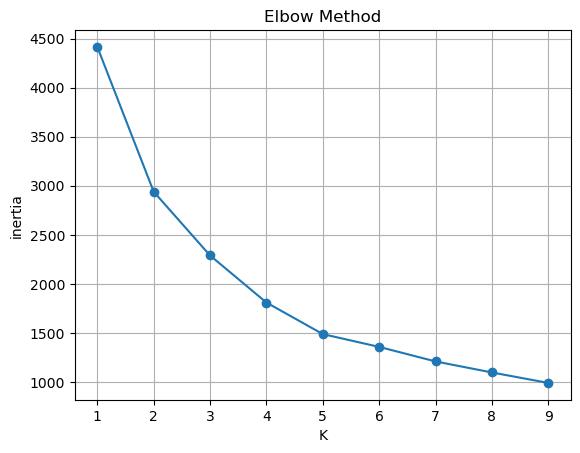

   k  inertia  Decrease from previous K
0  1   4415.0                       NaN
1  2   2939.0                    1476.0
2  3   2289.0                     650.0
3  4   1810.0                     480.0
4  5   1488.0                     322.0
5  6   1358.0                     130.0
6  7   1209.0                     148.0
7  8   1097.0                     112.0
8  9    990.0                     107.0


In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ks = range(1, 10)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]

plt.plot(ks, inertia, 'o-')
plt.xlabel('K'); plt.ylabel('inertia'); plt.title('Elbow Method')
plt.xticks(ks); plt.grid(True); plt.show()

print(pd.DataFrame({'k': ks, 'inertia': inertia,
                    'Decrease from previous K': pd.Series(inertia).diff().abs()}).round(0))

PCA Elbow

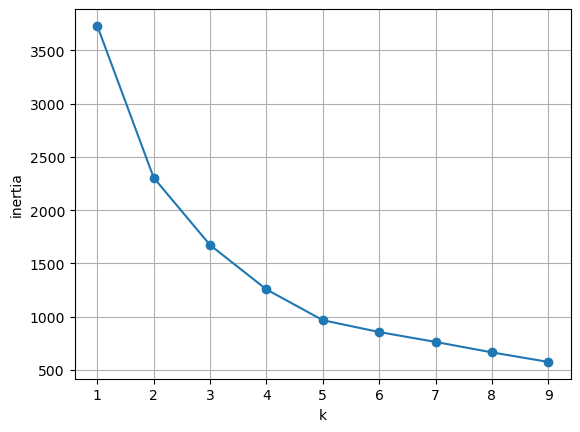

In [10]:
from sklearn.decomposition import PCA

Z = PCA(n_components=3).fit_transform(X)  

inertia = [KMeans(k, n_init=10, random_state=42).fit(Z).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('inertia'); plt.grid();plt.show()

In [6]:
km = KMeans(n_clusters=5, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X)

print(df['cluster'].value_counts().sort_index())      # จำนวนเครื่องในแต่ละกลุ่ม

# ศูนย์กลางของแต่ละกลุ่ม แปลงกลับเป็นหน่วยเดิม
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features).round(1)
centers['n'] = df['cluster'].value_counts().sort_index().values
print(centers)

# เรียงเลขกลุ่มใหม่ตามราคากลาง (0 = ถูกสุด ... 4 = แพงสุด)
order = df.groupby('cluster')['price'].median().sort_values().index
df['cluster'] = df['cluster'].map({old: new for new, old in enumerate(order)})

cluster
0    262
1    293
2     72
3    214
4     42
Name: count, dtype: int64
   ram_gb  threads  gpu_dedicated  display_size  resolution_width    n
0    13.8     14.4            1.0          15.8            1986.0  262
1    10.3      9.3           -0.0          15.6            1876.6  293
2    16.6     15.6            0.2          14.7            3005.3   72
3    11.9      9.9            0.0          13.9            1841.7  214
4    32.8     23.9            0.9          16.0            2703.2   42


           n  ram_gb  threads  gpu_dedicated  display_size  resolution_width  \
cluster                                                                        
0        293    10.3      9.3            0.0          15.6            1876.6   
1        214    11.9      9.9            0.0          13.9            1841.7   
2        262    13.8     14.4            1.0          15.8            1986.0   
3         72    16.6     15.6            0.2          14.7            3005.3   
4         42    32.8     23.9            0.9          16.0            2703.2   

         price_min  price_median  price_max  
cluster                                      
0             5597       15400.0     145250  
1             3846       19563.5      81111  
2            15746       27122.0      93800  
3            15396       37553.5     108322  
4            22747       85523.5     157514  


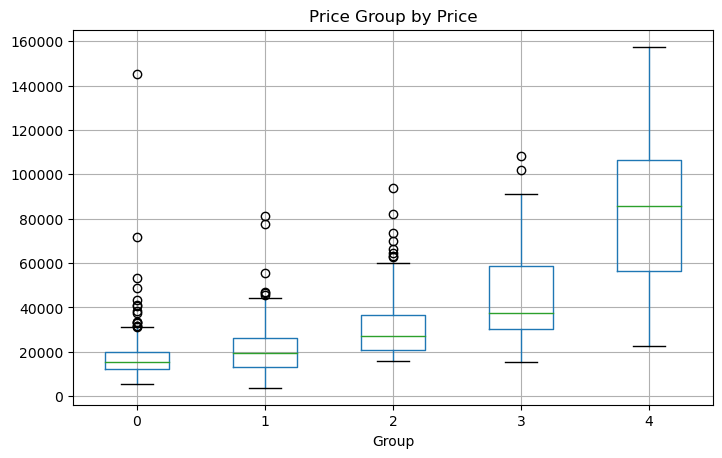

--- กลุ่ม 0
      brand                                   name   price
342      HP         Chromebook 15a-na0012TU Laptop    5597
757  Lenovo  IdeaPad Slim 3 2023 82X70033IN Laptop   15400
597      HP    Spectre 17-cs0097nr Foldable Laptop  145250
--- กลุ่ม 1
       brand                         name  price
10   Ultimus  Pro NU14U3INC43BN-CS Laptop   3846
486       HP  Pavilion 14-EC1019AU Laptop  19597
680       HP          Dragonfly G4 Laptop  81111
--- กลุ่ม 2
    brand                                      name  price
690  Acer     Aspire 5 A515-56G NX.AT2SI.001 Laptop  15746
159  Asus  Vivobook 16X 2023 K3605ZC-MB541WS Laptop  27297
541    HP            Omen 17-ck2008AX Gaming Laptop  93800
--- กลุ่ม 3
      brand                                name   price
65   Xiaomi           Redmi Book 14 2023 Laptop   15396
871    Acer           Swift Edge 16 2023 Laptop   37590
460   Apple  MacBook Pro 16 inch MK1A3HN Laptop  108322
--- กลุ่ม 4
       brand                                 nam

In [12]:
# 6.1 ตารางโปรไฟล์ของแต่ละกลุ่ม
profile = df.groupby('cluster').agg(
    n=('price', 'size'),
    ram_gb=('ram_gb', 'mean'), threads=('threads', 'mean'),
    gpu_dedicated=('gpu_dedicated', 'mean'), display_size=('display_size', 'mean'),
    resolution_width=('resolution_width', 'mean'),
    price_min=('price', 'min'), price_median=('price', 'median'), price_max=('price', 'max')
).round(1)
print(profile)

# 6.2 Boxplot ราคาของแต่ละกลุ่ม
df.boxplot(column='price', by='cluster', figsize=(8, 5))
plt.suptitle(''); plt.title('Price Group by Price'); plt.xlabel('Group'); plt.show()

# 6.3 ตัวอย่างเครื่อง: ถูกสุด / กลาง / แพงสุดของแต่ละกลุ่ม
for c in range(5):
    d = df[df['cluster'] == c].sort_values('price')
    print(f'--- กลุ่ม {c}')
    print(d.iloc[[0, len(d) // 2, -1]][['brand', 'name', 'price']])

# 6.4 แบรนด์ที่พบมากสุด 3 อันดับ
print(df.groupby('cluster')['brand'].agg(lambda s: s.value_counts().head(3).to_dict()))
# 6.5 ตั้งชื่อกลุ่ม (ตรวจตารางโปรไฟล์ก่อนว่าตรงกัน)
names = {0: 'Entry', 1: 'พกพา จอเล็ก', 2: 'การ์ดจอแยก', 3: 'จอละเอียดสูง', 4: 'สเปกสูงสุด'}
df['segment'] = df['cluster'].map(names)

ValueError: กรุณารัน Cell 9 เพื่อสร้าง cluster ก่อน

Price Prediction

In [7]:
from sklearn.naive_bayes import GaussianNB

df['log_price'] = np.log(df['price'])
nb = GaussianNB().fit(df[['log_price']], df['cluster'])      # เรียนรู้ราคาของแต่ละกลุ่ม

# สเปกทั่วไปของแต่ละกลุ่ม
prof = df.groupby('cluster').agg(ram=('ram_gb', 'median'), thr=('threads', 'median'),
                                 gpu=('gpu_dedicated', 'mean'), disp=('display_size', 'median'),
                                 resw=('resolution_width', 'median'))

def specs_from_price(price, show=2):
    p = nb.predict_proba(pd.DataFrame({'log_price': [np.log(price)]}))[0]
    print(f'งบ {price:,.0f} บาท')
    for c in np.argsort(-p)[:show]:                 # แสดง 2 กลุ่มที่เป็นไปได้สูงสุด
        r = prof.loc[c]
        print(f'  {p[c]:.0%} กลุ่ม {c} {names[c]}: RAM {r.ram:.0f} GB, {r.thr:.0f} threads, '
              f'GPU แยก {r.gpu:.0%}, จอ {r.disp:.1f}", {r.resw:.0f}px')

specs_from_price(25000)

KeyError: 'cluster'